In [1]:
# Data Loading
# Mengimpor library untuk mengolah data
import pandas as pd
import numpy as np

# Mengimpor library untuk visualisasi data
import matplotlib.pyplot as plt
import seaborn as sns

# Mengimpor fungsi pembagi data dan standardisasi dari scikit-learn
from sklearn.model_selection import GroupShuffleSplit
from sklearn.preprocessing import StandardScaler

# Mengabaikan pesan peringatan agar output lebih bersih
import warnings
warnings.filterwarnings('ignore')

# Menampilkan semua kolom (maksimal 50) saat DataFrame dicetak
pd.set_option('display.max_columns', 50)

# Mengatur tema grafik
sns.set_theme(style='whitegrid')

# Menetapkan random_state agar hasil pembagian data selalu sama
RANDOM_STATE = 42

In [2]:
# Membaca file CSV ke dalam DataFrame
coffee_value_benchmark = pd.read_csv('coffee_value_benchmark.csv')

# Menampilkan jumlah baris dan kolom
print('Ukuran data (baris, kolom):', coffee_value_benchmark.shape)

# Menampilkan 5 baris pertama
coffee_value_benchmark.head()

Ukuran data (baris, kolom): (35700, 36)


,record_id,lot_id,harvest_season,harvest_calendar_year,harvest_month,country_of_origin,farm_type,farm_size_hectares,tree_age_years,altitude_mean_meters,species,avg_temp_c,avg_annual_rainfall_mm,humidity_pct,processing_method,drying_method,drying_duration_days,storage_months,storage_conditions,bean_size_screen,moisture_pct,bean_density_g_ml,defect_rate_pct,traceability_level,certification,intended_buyer_segment,lot_size_kg,roast_level,acidity_score,sweetness_score,body_score,aroma_score,flavor_score,coffee_quality_score,quality_grade,price_usd_per_kg
0,REC-0000001,LOT-0032936,2020/21,2020,10,Vietnam,Smallholder,0.58,28.0,1961.0,Arabica,16.9,2073.0,83.5,Natural,Mechanical,15.7,3,Basic,16,11.26,1.165,3.6,Country,NaN,Commodity,26433.0,Medium,7.95,7.30,8.45,7.35,7.37,78.01,Very Good,2.43
1,REC-0000002,LOT-0030952,2021/22,2022,1,Honduras,Smallholder,1.12,2.0,1257.0,Arabica,16.5,2059.0,NaN,Anaerobic,Patio,10.9,6,Basic,18,11.51,1.112,4.9,Country,NaN,Commodity,25446.0,Medium,7.62,8.17,7.45,7.80,6.88,75.62,Good,4.06
2,REC-0000003,LOT-0018572,2020/21,2020,11,Vietnam,Cooperative,13.82,5.0,557.0,Robusta,23.3,1973.0,74.8,Washed,Patio,10.8,4,Climate Controlled,19,NaN,1.094,0.0,Cooperative,NaN,Premium,15707.0,Medium,8.47,8.83,8.13,7.70,8.10,72.41,Commercial,4.26
3,REC-0000004,LOT-0005318,2021/22,2021,10,Vietnam,Cooperative,9.96,22.0,652.0,Robusta,24.6,2375.0,82.8,Washed,Patio,9.5,5,Basic,17,11.59,1.100,0.8,Cooperative,NaN,Commodity,2879.0,Medium,7.54,8.12,8.21,7.77,7.13,75.67,Good,3.60
4,REC-0000005,LOT-0006317,2021/22,2021,7,Brazil,Smallholder,1.90,11.0,971.0,Robusta,18.7,860.0,68.0,Honey,Patio,10.9,3,Basic,16,10.86,1.095,2.5,Country,NaN,Commodity,9561.0,Medium,6.70,8.08,8.68,7.38,7.16,73.77,Good,4.16


In [3]:
# Menampilkan informasi kolom: nama, jumlah data terisi, dan tipe data
coffee_value_benchmark.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 35700 entries, 0 to 35699
Data columns (total 36 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   record_id               35700 non-null  object 
 1   lot_id                  35700 non-null  object 
 2   harvest_season          35700 non-null  object 
 3   harvest_calendar_year   35700 non-null  int64  
 4   harvest_month           35700 non-null  int64  
 5   country_of_origin       35700 non-null  object 
 6   farm_type               35700 non-null  object 
 7   farm_size_hectares      35700 non-null  float64
 8   tree_age_years          35700 non-null  float64
 9   altitude_mean_meters    35700 non-null  float64
 10  species                 35700 non-null  object 
 11  avg_temp_c              35700 non-null  float64
 12  avg_annual_rainfall_mm  33881 non-null  float64
 13  humidity_pct            33418 non-null  float64
 14  processing_method       35700 non-null

In [4]:
# Menampilkan ringkasan statistik semua kolom (numerik dan kategorikal)
coffee_value_benchmark.describe(include='all').T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
record_id,35700,35700,REC-0000001,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
lot_id,35700,35000,LOT-0025302,3,NaN,NaN,NaN,NaN,NaN,NaN,NaN
harvest_season,35700,5,2021/22,10747,NaN,NaN,NaN,NaN,NaN,NaN,NaN
harvest_calendar_year,35700.0,NaN,NaN,NaN,2021.470308,1.282059,2019.0,2021.0,2021.0,2022.0,2024.0
harvest_month,35700.0,NaN,NaN,NaN,8.091401,3.230757,1.0,6.0,9.0,11.0,12.0
country_of_origin,35700,7,Brazil,11510,NaN,NaN,NaN,NaN,NaN,NaN,NaN
farm_type,35700,3,Smallholder,19758,NaN,NaN,NaN,NaN,NaN,NaN,NaN
farm_size_hectares,35700.0,NaN,NaN,NaN,16.588095,37.377621,0.35,1.57,2.75,14.99,920.26
tree_age_years,35700.0,NaN,NaN,NaN,15.140364,8.013493,2.0,9.0,14.0,19.0,50.0
altitude_mean_meters,35700.0,NaN,NaN,NaN,1145.550896,531.533991,150.0,692.0,1071.0,1616.0,2726.0


In [5]:
# Periksa Mising value dan duplikat
# Menghitung jumlah missing values di setiap kolom
missing_values = coffee_value_benchmark.isnull().sum()

# Menghitung persentase missing values terhadap total baris
missing_percentage = (missing_values / len(coffee_value_benchmark)) * 100

# Menggabungkan jumlah dan persentase ke dalam satu tabel, diurutkan dari yang terbanyak
missing_data = pd.DataFrame({
    'Missing Values': missing_values,
    'Percentage': missing_percentage.round(2)
}).sort_values(by='Missing Values', ascending=False)

# Menampilkan hanya kolom yang memiliki missing values
missing_data[missing_data['Missing Values'] > 0]

,Missing Values,Percentage
certification,21723,60.85
humidity_pct,2282,6.39
avg_annual_rainfall_mm,1819,5.10
bean_density_g_ml,1632,4.57
moisture_pct,1612,4.52


In [6]:
# Menyusun daftar kolom tanpa record_id (record_id selalu unik sehingga tidak ikut dibandingkan)
kolom_tanpa_id = [kolom for kolom in coffee_value_benchmark.columns if kolom != 'record_id']

# Mengidentifikasi baris duplikat persis
duplicates = coffee_value_benchmark.duplicated(subset=kolom_tanpa_id)
print('Jumlah baris duplikat persis:', duplicates.sum())

# Mengecek lot_id yang muncul lebih dari sekali
print('Jumlah lot_id yang berulang :', coffee_value_benchmark['lot_id'].duplicated().sum())
print('Jumlah lot_id unik          :', coffee_value_benchmark['lot_id'].nunique())

Jumlah baris duplikat persis: 350
Jumlah lot_id yang berulang : 700
Jumlah lot_id unik          : 35000


In [7]:
# Temuan awal

# Ada 5 kolom dengan missing values: avg_annual_rainfall_mm, humidity_pct, moisture_pct, bean_density_g_ml (masing-masing sekitar 1.600-2.300 baris), dan certification (21.723 baris, 61%).
# certification kosong berarti tidak bersertifikat, bukan data hilang, jadi diisi kategori 'None'.
# Ada 350 baris duplikat persis. Selain itu ada 350 baris lain dengan lot_id yang sama tetapi nilai moisture_pct / defect_rate_pct sedikit berbeda (kemungkinan pengukuran ulang lot yang sama). Ini penting saat Data Splitting.

In [8]:
# Data Cleaning dan transformation

In [9]:
# Langkah 1 - Menghapus kolom ID dan baris duplikat. record_id hanya penanda baris sehingga dibuang; baris yang isinya persis sama dihapus.¶

In [10]:
# Membuat salinan data supaya data asli tidak berubah, sekaligus membuang kolom record_id
df = coffee_value_benchmark.drop(columns=['record_id']).copy()

# Menghapus baris duplikat lalu merapikan ulang nomor indeks
df = df.drop_duplicates().reset_index(drop=True)

# Menampilkan jumlah baris sebelum dan sesudah menghapus duplikat
print('Baris sebelum:', len(coffee_value_benchmark), '| sesudah hapus duplikat:', len(df))

Baris sebelum: 35700 | sesudah hapus duplikat: 35350


In [11]:
# Langkah 2 - Mengisi missing values. `certification` diisi `'None'` (kosong = tidak bersertifikat), sedangkan kolom numerik diisi **median** karena tidak terpengaruh outlier.

In [12]:
# Mengisi missing values kolom certification dengan kategori 'None'
df['certification'] = df['certification'].fillna('None')

# Mencari kolom yang masih memiliki missing values (semuanya numerik)
missing_values = df.isnull().sum()
numeric_missing = missing_values[missing_values > 0].index
print('Kolom yang diisi median:', list(numeric_missing))

# Mengisi missing values pada kolom tersebut dengan nilai median masing-masing kolom
df[numeric_missing] = df[numeric_missing].fillna(df[numeric_missing].median())

# Memeriksa sisa missing values (harus 0)
print('Sisa missing values:', df.isnull().sum().sum())

Kolom yang diisi median: ['avg_annual_rainfall_mm', 'humidity_pct', 'moisture_pct', 'bean_density_g_ml']
Sisa missing values: 0


In [13]:
# Langkah 3 - Menangani outlier dengan capping IQR.** Nilai di luar batas `Q1 - 1.5*IQR` dan `Q3 + 1.5*IQR` dipotong ke batas tersebut, sehingga jumlah baris tetap.
 # Yang di-cap hanya **fitur numerik**; kolom target, skor rasa, dan kolom kalender panen tidak ikut agar nilai aslinya tidak berubah.

In [14]:
# Mendefinisikan kolom target (hasil yang ingin dianalisis/diprediksi)
target_cols = ['coffee_quality_score', 'price_usd_per_kg']

# Mendefinisikan kolom skor rasa (bagian dari penilaian kualitas)
score_cols = ['acidity_score', 'sweetness_score', 'body_score', 'aroma_score', 'flavor_score']

# Mendefinisikan kolom kalender panen
calendar_cols = ['harvest_calendar_year', 'harvest_month']

# Memilih fitur numerik: semua kolom numerik kecuali target, skor rasa, dan kalender panen
numeric_features = [
    kolom for kolom in df.select_dtypes(include='number').columns
    if kolom not in target_cols + score_cols + calendar_cols
]

# Menampilkan jumlah dan nama fitur numerik
print(len(numeric_features), 'fitur numerik:', numeric_features)

13 fitur numerik: ['farm_size_hectares', 'tree_age_years', 'altitude_mean_meters', 'avg_temp_c', 'avg_annual_rainfall_mm', 'humidity_pct', 'drying_duration_days', 'storage_months', 'bean_size_screen', 'moisture_pct', 'bean_density_g_ml', 'defect_rate_pct', 'lot_size_kg']


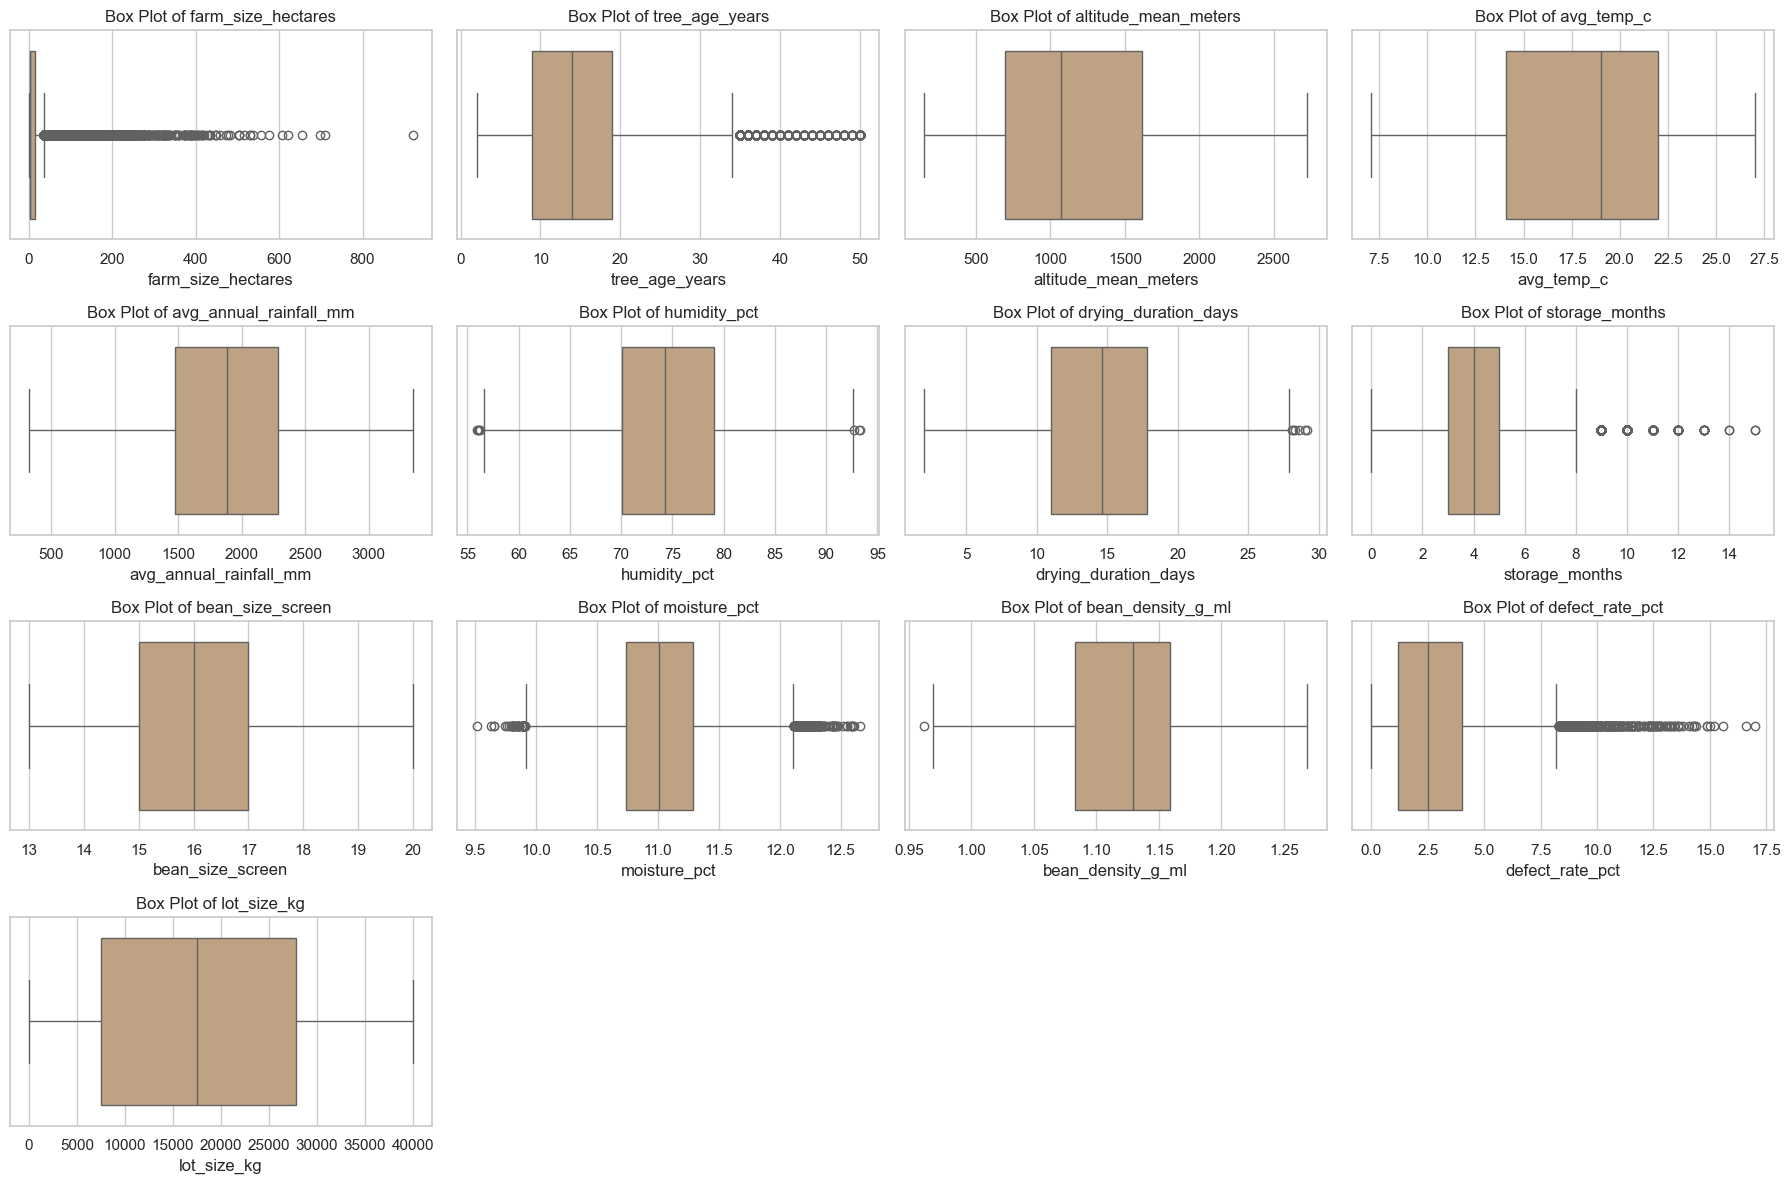

In [15]:
# Menentukan jumlah kolom dan baris untuk grid subplot
n_cols = 4
n_rows = -(-len(numeric_features) // n_cols)   # pembagian dibulatkan ke atas

# Membuat grid subplot
fig, axes = plt.subplots(n_rows, n_cols, figsize=(18, n_rows * 3))

# Membuat box plot untuk setiap fitur numerik (sebelum capping)
for ax, feature in zip(axes.flatten(), numeric_features):
    sns.boxplot(x=df[feature], ax=ax, color='#c8a27a')
    ax.set_title(f'Box Plot of {feature}')

# Menghapus subplot kosong yang tidak terpakai
for ax in axes.flatten()[len(numeric_features):]:
    ax.remove()

# Merapikan tata letak dan menampilkan grafik
plt.tight_layout()
plt.show()

In [16]:
# Menghitung kuartil pertama (Q1) dan kuartil ketiga (Q3) setiap fitur
Q1 = df[numeric_features].quantile(0.25)
Q3 = df[numeric_features].quantile(0.75)

# Menghitung IQR (rentang antar kuartil)
IQR = Q3 - Q1

# Menghitung batas bawah dan batas atas yang masih dianggap wajar
batas_bawah = Q1 - 1.5 * IQR
batas_atas = Q3 + 1.5 * IQR

# Menghitung jumlah nilai outlier pada setiap kolom
jumlah_outlier = ((df[numeric_features] < batas_bawah) | (df[numeric_features] > batas_atas)).sum()
print('Jumlah nilai outlier per kolom (yang lebih dari 0):')
print(jumlah_outlier[jumlah_outlier > 0])

# Memotong nilai outlier ke batas bawah/atas (capping)
df[numeric_features] = df[numeric_features].clip(lower=batas_bawah, upper=batas_atas, axis=1)

# Memastikan jumlah baris tidak berubah
print()
print('Jumlah baris setelah capping:', len(df))

Jumlah nilai outlier per kolom (yang lebih dari 0):
farm_size_hectares      4141
tree_age_years           955
humidity_pct               7
drying_duration_days       6
storage_months           730
moisture_pct             262
bean_density_g_ml          1
defect_rate_pct          610
dtype: int64

Jumlah baris setelah capping: 35350


In [17]:
## 3.2 Transformation (encoding)
# Model hanya bisa memproses angka, sehingga kolom kategorikal diubah menjadi numerik:

# - **Ordinal** (punya urutan): `roast_level`, `traceability_level`, `intended_buyer_segment`, `quality_grade`, serta kolom biner `species` dan `storage_conditions` → dipetakan ke angka sesuai urutan. Cara ini dipilih (bukan `LabelEncoder`) karena `LabelEncoder` memberi angka berdasarkan urutan abjad, yang bisa salah (mis. Commercial, Excellent, Exceptional, Good, Very Good bukan urutan kualitas).
# - **Nominal** (tanpa urutan): `country_of_origin`, `farm_type`, `processing_method`, `drying_method`, `certification` → **One-Hot Encoding** dengan `pd.get_dummies`.
# - `harvest_season` dibuang karena informasinya sudah ada di `harvest_calendar_year`.
# - `df_clean` disimpan dengan label asli untuk EDA/ExDA, sedangkan `df_encoded` adalah versi numerik untuk modeling.

In [18]:
# Menyimpan data yang sudah bersih dengan label asli (untuk EDA dan ExDA)
df_clean = df.copy()

# Mendefinisikan urutan kategori untuk kolom ordinal
ordinal_maps = {
    'roast_level': {'Light': 0, 'Medium': 1, 'Dark': 2},
    'traceability_level': {'Country': 0, 'Region': 1, 'Cooperative': 2, 'Farm': 3, 'Microlot': 4},
    'intended_buyer_segment': {'Commodity': 0, 'Premium': 1, 'Specialty': 2},
    'quality_grade': {'Commercial': 0, 'Good': 1, 'Very Good': 2, 'Excellent': 3, 'Exceptional': 4},
    'species': {'Robusta': 0, 'Arabica': 1},
    'storage_conditions': {'Basic': 0, 'Climate Controlled': 1},
}

# Mendefinisikan kolom nominal yang akan di-One-Hot
nominal_cols = ['country_of_origin', 'farm_type', 'processing_method', 'drying_method', 'certification']

In [19]:
# Membuat salinan data untuk proses encoding
df_encoded = df.copy()

# Mengubah kolom ordinal menjadi angka sesuai urutan yang sudah didefinisikan
for kolom, pemetaan in ordinal_maps.items():
    df_encoded[kolom] = df_encoded[kolom].map(pemetaan)

# Memastikan semua kategori ordinal berhasil dipetakan (tidak ada NaN)
assert df_encoded[list(ordinal_maps)].isnull().sum().sum() == 0, 'Ada kategori yang belum terpetakan'

# Membuang harvest_season karena sudah diwakili harvest_calendar_year
df_encoded = df_encoded.drop(columns=['harvest_season'])

# One-Hot Encoding untuk kolom nominal (drop_first=True menghindari kolom berlebih)
df_encoded = pd.get_dummies(df_encoded, columns=nominal_cols, drop_first=True, dtype=int)

# Menampilkan ukuran data dan 5 baris pertama
print('df_clean:', df_clean.shape, '| df_encoded:', df_encoded.shape)
df_encoded.head()

df_clean: (35350, 35) | df_encoded: (35350, 46)


,lot_id,harvest_calendar_year,harvest_month,farm_size_hectares,tree_age_years,altitude_mean_meters,species,avg_temp_c,avg_annual_rainfall_mm,humidity_pct,drying_duration_days,storage_months,storage_conditions,bean_size_screen,moisture_pct,bean_density_g_ml,defect_rate_pct,traceability_level,intended_buyer_segment,lot_size_kg,roast_level,acidity_score,sweetness_score,body_score,aroma_score,flavor_score,coffee_quality_score,quality_grade,price_usd_per_kg,country_of_origin_Colombia,country_of_origin_Ethiopia,country_of_origin_Honduras,country_of_origin_Indonesia,country_of_origin_Kenya,country_of_origin_Vietnam,farm_type_Estate,farm_type_Smallholder,processing_method_Honey,processing_method_Natural,processing_method_Washed,drying_method_Patio,drying_method_Raised Bed,certification_Multiple,certification_None,certification_Organic,certification_Rainforest Alliance
0,LOT-0032936,2020,10,0.58,28.0,1961.0,1,16.9,2073.0,83.50,15.7,3,0,16,11.26,1.165,3.6,0,0,26433.0,1,7.95,7.30,8.45,7.35,7.37,78.01,2,2.43,0,0,0,0,0,1,0,1,0,1,0,0,0,0,1,0,0
1,LOT-0030952,2022,1,1.12,2.0,1257.0,1,16.5,2059.0,74.25,10.9,6,0,18,11.51,1.112,4.9,0,0,25446.0,1,7.62,8.17,7.45,7.80,6.88,75.62,1,4.06,0,0,1,0,0,0,0,1,0,0,0,1,0,0,1,0,0
2,LOT-0018572,2020,11,13.82,5.0,557.0,0,23.3,1973.0,74.80,10.8,4,1,19,11.01,1.094,0.0,2,1,15707.0,1,8.47,8.83,8.13,7.70,8.10,72.41,0,4.26,0,0,0,0,0,1,0,0,0,0,1,1,0,0,1,0,0
3,LOT-0005318,2021,10,9.96,22.0,652.0,0,24.6,2375.0,82.80,9.5,5,0,17,11.59,1.100,0.8,2,0,2879.0,1,7.54,8.12,8.21,7.77,7.13,75.67,1,3.60,0,0,0,0,0,1,0,0,0,0,1,1,0,0,1,0,0
4,LOT-0006317,2021,7,1.90,11.0,971.0,0,18.7,860.0,68.00,10.9,3,0,16,10.86,1.095,2.5,0,0,9561.0,1,6.70,8.08,8.68,7.38,7.16,73.77,1,4.16,0,0,0,0,0,0,0,1,1,0,0,1,0,0,1,0,0


In [20]:
# Latihan EDA

In [21]:
### 4.1 Memeriksa kembali missing values setelah cleaning

In [22]:
# Menghitung jumlah dan persentase missing values di setiap kolom pada data bersih
missing_values = df_clean.isnull().sum()
missing_percentage = (missing_values / len(df_clean)) * 100
missing_data = pd.DataFrame({
    'Missing Values': missing_values,
    'Percentage': missing_percentage
}).sort_values(by='Missing Values', ascending=False)

# Menampilkan kolom dengan missing values (tabel kosong berarti sudah bersih)
missing_data[missing_data['Missing Values'] > 0]

,Missing Values,Percentage


In [23]:
## 4.2 Distribusi variabel numerik

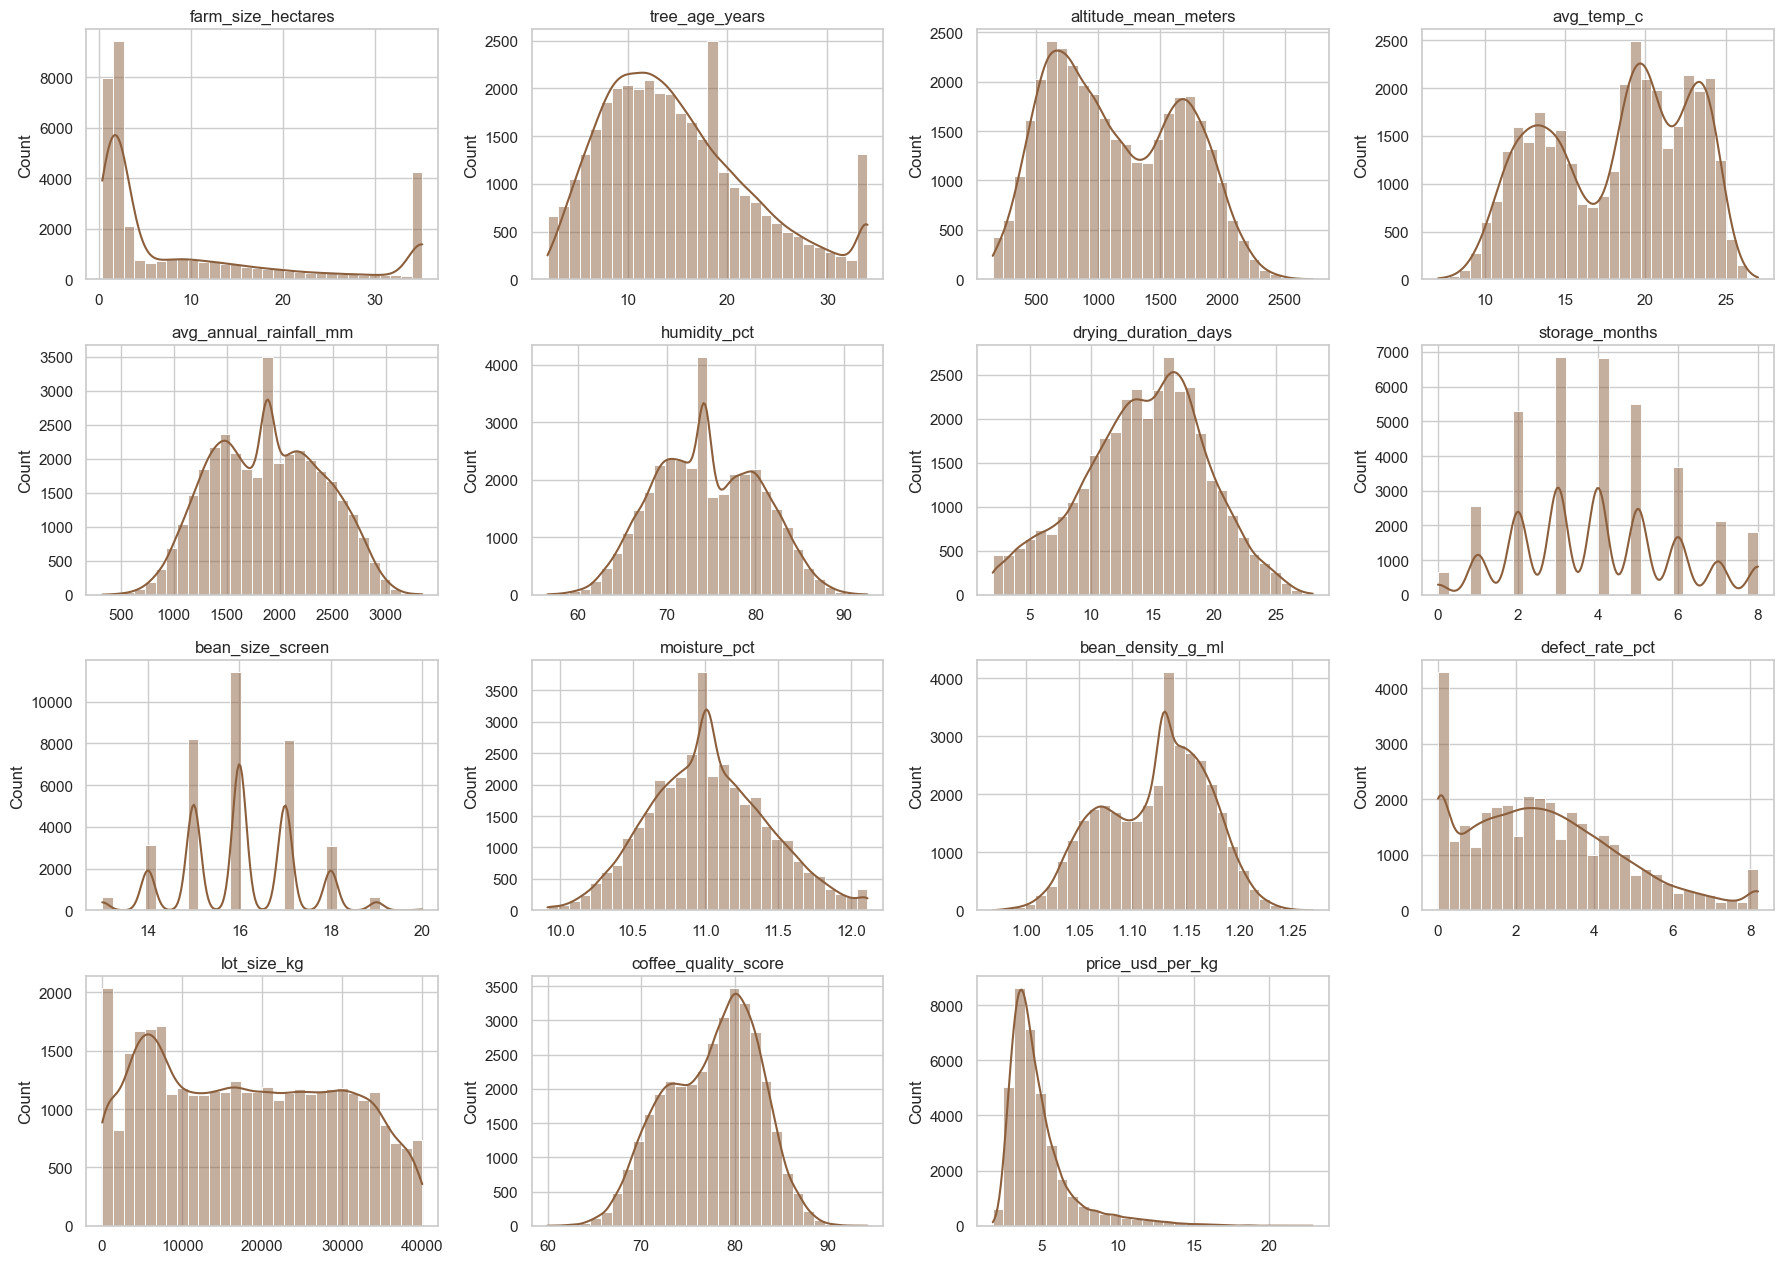

Skewness target:
coffee_quality_score   -0.26
price_usd_per_kg        2.32
dtype: float64


In [24]:
# Menentukan variabel numerik yang akan digambar: fitur numerik dan kolom target
eda_num = numeric_features + target_cols

# Menentukan jumlah kolom dan baris grid subplot
n_cols = 4
n_rows = -(-len(eda_num) // n_cols)

# Membuat grid subplot
fig, axes = plt.subplots(n_rows, n_cols, figsize=(18, n_rows * 3.2))

# Membuat histogram dan kurva KDE untuk setiap variabel
for ax, kolom in zip(axes.flatten(), eda_num):
    sns.histplot(df_clean[kolom], bins=30, kde=True, ax=ax, color='#8b5e3c')
    ax.set_title(kolom)
    ax.set_xlabel('')

# Menghapus subplot yang tidak terpakai
for ax in axes.flatten()[len(eda_num):]:
    ax.remove()

# Merapikan layout dan menampilkan grafik
plt.tight_layout()
plt.show()

# Menghitung skewness (kemiringan) kolom target
print('Skewness target:')
print(df_clean[target_cols].skew().round(2))

In [25]:
# 4.3 Distribusi variabel kategorikal

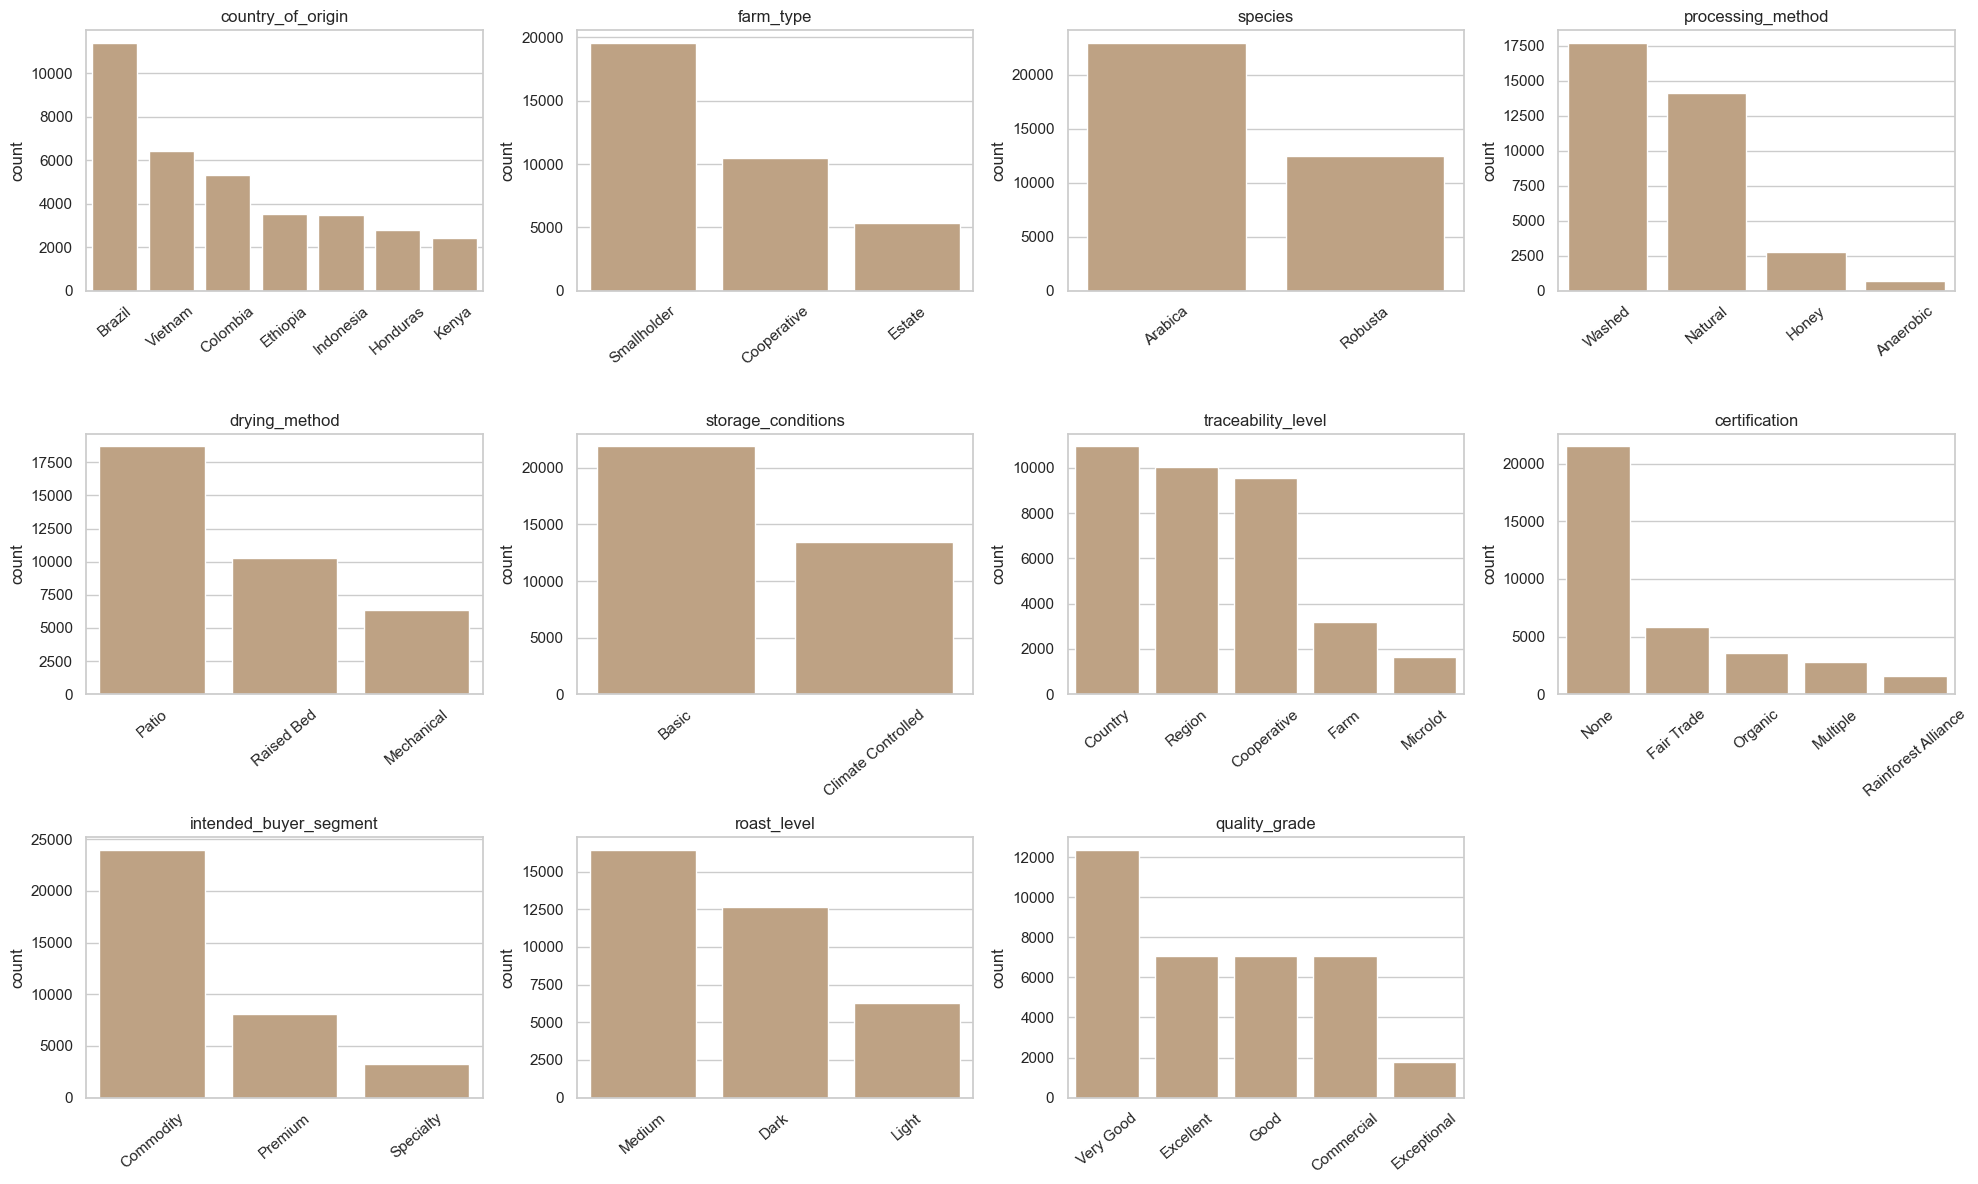

In [26]:
# Menentukan kolom kategorikal yang akan digambar
cat_plot = ['country_of_origin', 'farm_type', 'species', 'processing_method', 'drying_method',
            'storage_conditions', 'traceability_level', 'certification',
            'intended_buyer_segment', 'roast_level', 'quality_grade']

# Membuat grid subplot 3 baris x 4 kolom
fig, axes = plt.subplots(3, 4, figsize=(20, 12))

# Membuat grafik batang jumlah data untuk setiap kategori
for ax, kolom in zip(axes.flatten(), cat_plot):
    urutan = df_clean[kolom].value_counts().index   # urut dari jumlah terbanyak
    sns.countplot(data=df_clean, x=kolom, order=urutan, ax=ax, color='#c8a27a')
    ax.set_title(kolom)
    ax.set_xlabel('')
    ax.tick_params(axis='x', rotation=40)

# Menghapus subplot yang tidak terpakai
for ax in axes.flatten()[len(cat_plot):]:
    ax.remove()

# Merapikan layout dan menampilkan grafik
plt.tight_layout()
plt.show()

In [27]:
# 4.4 Korelasi antar variabel numerik

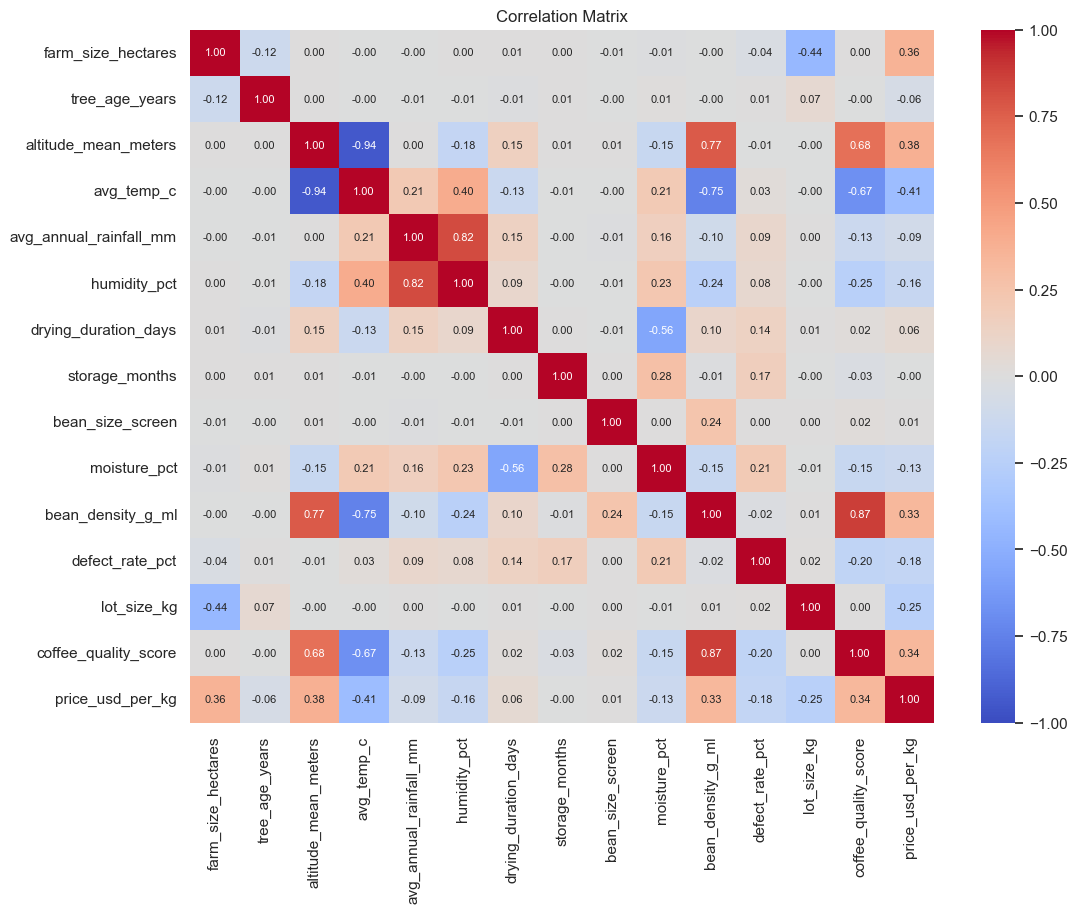

In [28]:
plt.figure(figsize=(12, 9))
correlation_matrix = df_clean[numeric_features + target_cols].corr()
sns.heatmap(correlation_matrix, annot=True, fmt='.2f', cmap='coolwarm',
            vmin=-1, vmax=1, annot_kws={'size': 8})
plt.title('Correlation Matrix')
plt.show()

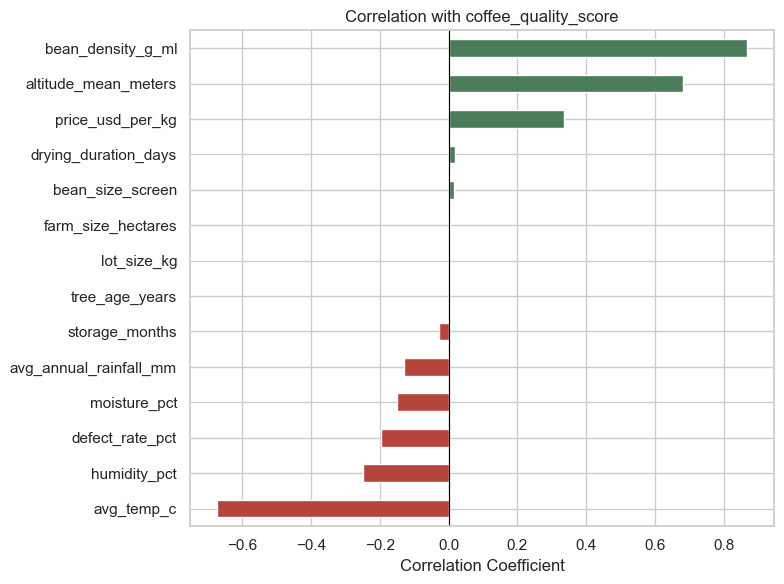

bean_density_g_ml         0.87
altitude_mean_meters      0.68
price_usd_per_kg          0.34
drying_duration_days      0.02
bean_size_screen          0.02
farm_size_hectares        0.00
tree_age_years           -0.00
lot_size_kg               0.00
storage_months           -0.03
avg_annual_rainfall_mm   -0.13
moisture_pct             -0.15
defect_rate_pct          -0.20
humidity_pct             -0.25
avg_temp_c               -0.67
dtype: float64

In [29]:
# Menghitung korelasi setiap fitur numerik (dan harga) dengan coffee_quality_score
target_corr = df_clean[numeric_features + ['price_usd_per_kg']].corrwith(df_clean['coffee_quality_score'])

# Mengurutkan hasil korelasi dari yang terkecil ke terbesar
target_corr_sorted = target_corr.sort_values()

# Menggambar grafik batang horizontal (hijau = positif, merah = negatif)
plt.figure(figsize=(8, 6))
target_corr_sorted.plot(kind='barh', color=['#b5453a' if v < 0 else '#4a7c59' for v in target_corr_sorted])
plt.title('Correlation with coffee_quality_score')
plt.xlabel('Correlation Coefficient')
plt.axvline(0, color='black', linewidth=0.8)
plt.tight_layout()
plt.show()

# Menampilkan nilai korelasi dari yang terbesar
target_corr.round(2).sort_values(ascending=False)

In [30]:
# Skor rasa (`acidity`, `aroma`, dst.) dan `quality_grade` **sengaja tidak dimasukkan** ke korelasi ini karena keduanya bagian dari penilaian kualitas itu sendiri, sehingga korelasinya tinggi dengan sendirinya dan tidak memberi insight.
# Variabel nominal juga tidak dihitung korelasinya; hubungannya dilihat lewat box plot di bawah.

In [31]:
# 4.5 Kualitas menurut kategori¶

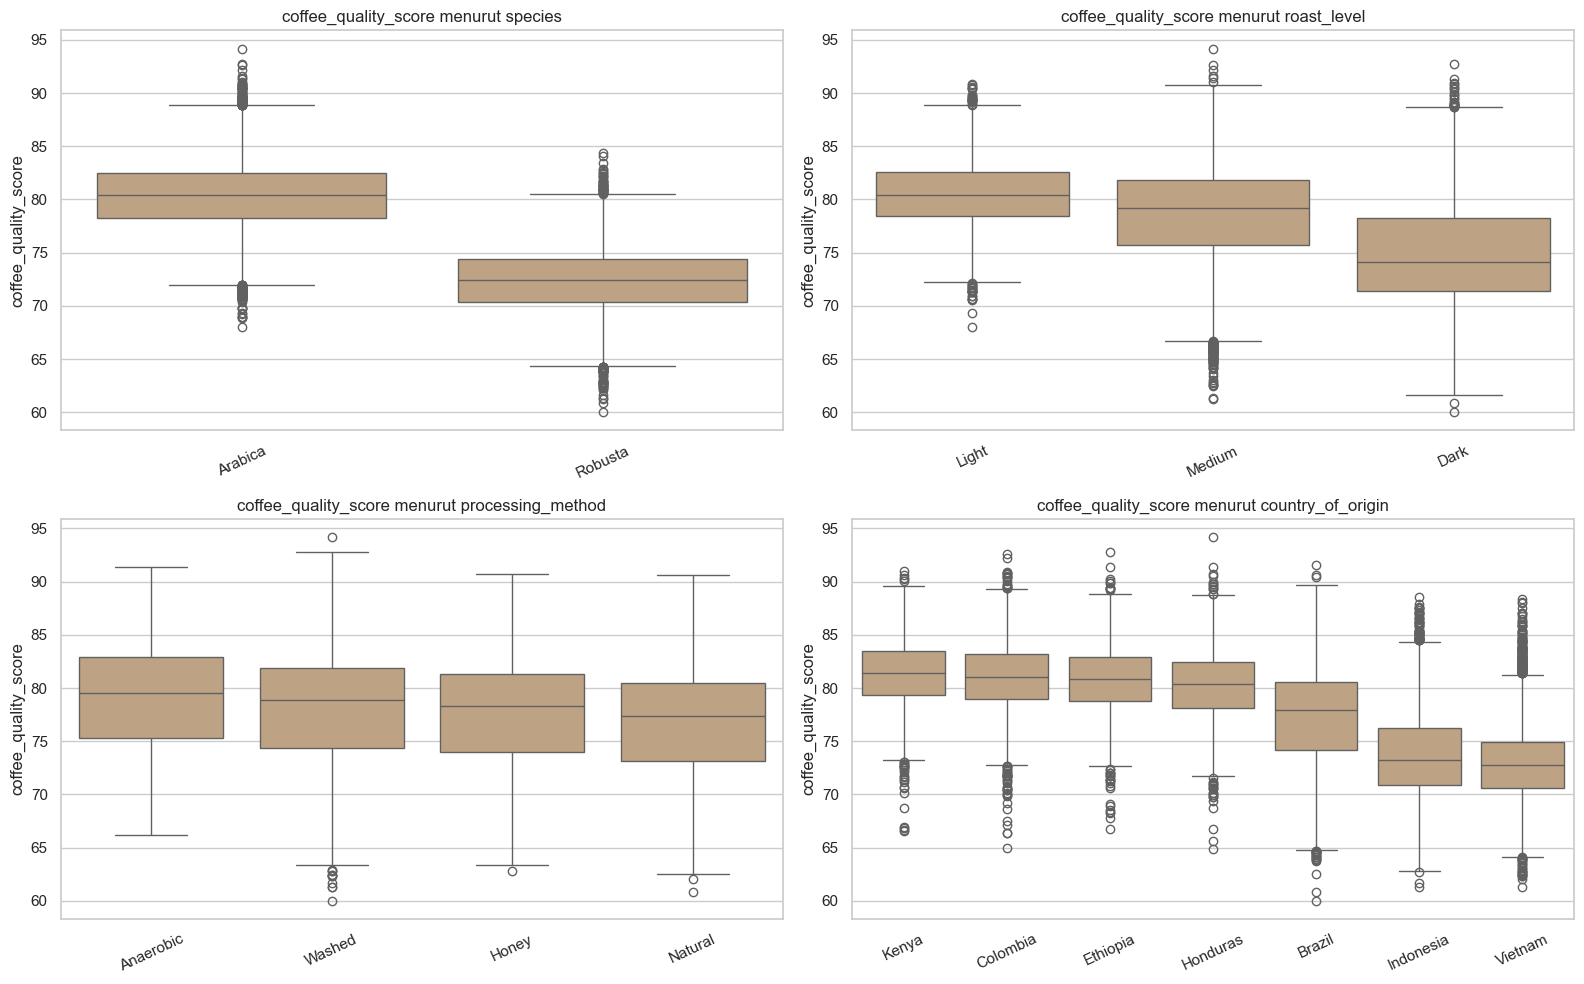

In [32]:
# Membuat grid subplot 2 x 2
fig, axes = plt.subplots(2, 2, figsize=(16, 10))

# Membuat box plot skor kualitas untuk empat kolom kategorikal
for ax, kolom in zip(axes.flatten(), ['species', 'roast_level', 'processing_method', 'country_of_origin']):
    if kolom == 'roast_level':
        urutan = ['Light', 'Medium', 'Dark']   # urutan alami tingkat sangrai
    else:
        urutan = df_clean.groupby(kolom)['coffee_quality_score'].mean().sort_values(ascending=False).index
    sns.boxplot(data=df_clean, x=kolom, y='coffee_quality_score', order=urutan, ax=ax, color='#c8a27a')
    ax.set_title(f'coffee_quality_score menurut {kolom}')
    ax.set_xlabel('')
    ax.tick_params(axis='x', rotation=25)

# Merapikan layout dan menampilkan grafik
plt.tight_layout()
plt.show()

In [33]:
# Menampilkan rata-rata skor kualitas, harga, dan jumlah data per kategori
for kolom in ['species', 'roast_level', 'processing_method', 'intended_buyer_segment', 'certification']:
    tabel = (df_clean.groupby(kolom)[['coffee_quality_score', 'price_usd_per_kg']]
             .agg(['mean', 'count']).round(2))
    display(tabel)

coffee_quality_score        price_usd_per_kg       
                        mean  count             mean  count
species                                                    
Arabica                80.41  22934             5.37  22934
Robusta                72.42  12416             3.77  12416

coffee_quality_score        price_usd_per_kg       
                            mean  count             mean  count
roast_level                                                    
Dark                       74.89  12628             4.03  12628
Light                      80.50   6267             6.62   6267
Medium                     78.57  16455             4.72  16455

coffee_quality_score        price_usd_per_kg       
                                  mean  count             mean  count
processing_method                                                    
Anaerobic                        79.15    709             5.77    709
Honey                            77.66   2762             5.05   2762
Natural                          76.83  14160             4.62  14160
Washed                           78.14  17719             4.89  17719

coffee_quality_score        price_usd_per_kg       
                                       mean  count             mean  count
intended_buyer_segment                                                    
Commodity                             76.84  23994             3.87  23994
Premium                               78.58   8064             5.49   8064
Specialty                             80.77   3292             9.97   3292

coffee_quality_score        price_usd_per_kg       
                                    mean  count             mean  count
certification                                                          
Fair Trade                         77.50   5836             4.58   5836
Multiple                           77.74   2774             6.19   2774
None                               77.57  21522             4.38  21522
Organic                            77.70   3603             5.74   3603
Rainforest Alliance                77.84   1615             6.94   1615

##### Ringkasan EDA
- **Kualitas** (`coffee_quality_score`) sedikit miring ke kiri (skewness sekitar -0,26), rata-rata sekitar 77-78. **Harga** miring tajam ke kanan (skewness sekitar 2,3): sebagian besar lot murah, sedikit lot sangat mahal.
- Korelasi terkuat dengan kualitas: **`bean_density_g_ml` (sekitar +0,87)**, **`altitude_mean_meters` (sekitar +0,68)**, dan **`avg_temp_c` (sekitar -0,67)**. `humidity_pct`, `defect_rate_pct`, dan `moisture_pct` berkorelasi negatif lemah.
- Korelasi setinggi itu sebagian besar dipengaruhi **spesies**: Arabica tumbuh lebih tinggi, di suhu lebih sejuk, dan bijinya lebih padat daripada Robusta (lihat ExDA, Temuan 2).
- Ukuran kebun, ukuran lot, umur pohon, dan lama simpan hampir tidak berkorelasi dengan kualitas.
- `altitude_mean_meters` dan `avg_temp_c` berkorelasi sangat kuat satu sama lain (sekitar -0,94), jadi keduanya hampir membawa informasi yang sama (*multikolinearitas*).
- `price_usd_per_kg` hanya berkorelasi sedang dengan kualitas (sekitar +0,34), jadi harga tidak sepenuhnya ditentukan oleh kualitas.
- Menurut kategori: **Arabica** jauh lebih tinggi dari Robusta, roast **Light** lebih tinggi dari Dark, dan negara berbeda cukup jauh (Kenya/Colombia/Ethiopia di atas, Vietnam/Indonesia di bawah).

##### 5. ExDA (*Explanatory Data Analysis*)
##### Jika EDA untuk *mencari tahu*, ExDA untuk *menjelaskan temuan* kepada pembaca: setiap grafik punya judul yang berisi pesan, lalu dijelaskan maknanya.

##### Temuan 1 - Spesies adalah pembeda terbesar kualitas dan harga

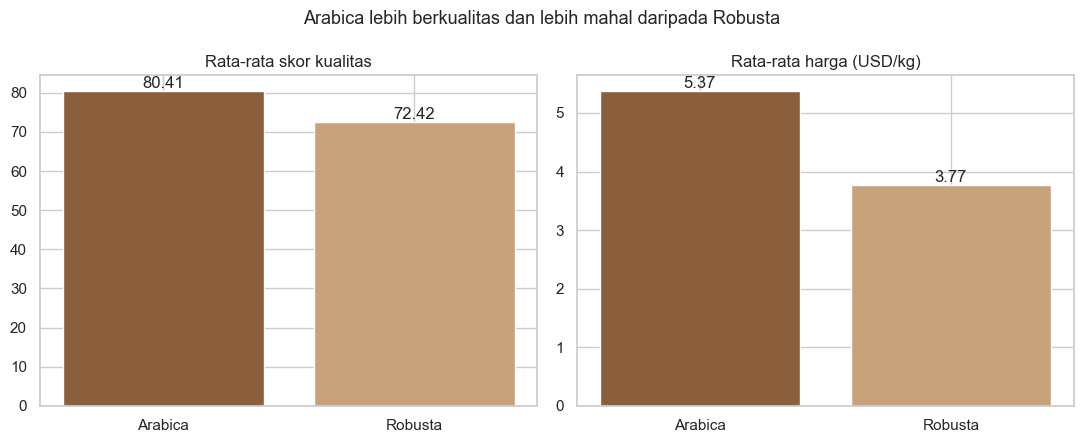

In [34]:
# Menghitung rata-rata skor kualitas dan harga untuk setiap spesies
agg = df_clean.groupby('species')[['coffee_quality_score', 'price_usd_per_kg']].mean()

# Membuat dua grafik batang berdampingan
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for ax, kolom, judul in zip(axes, ['coffee_quality_score', 'price_usd_per_kg'],
                            ['Rata-rata skor kualitas', 'Rata-rata harga (USD/kg)']):
    bars = ax.bar(agg.index, agg[kolom], color=['#8b5e3c', '#c8a27a'])
    ax.bar_label(bars, fmt='%.2f')   # menampilkan angka di atas batang
    ax.set_title(judul)

# Memberi judul utama berupa pesan temuan
plt.suptitle('Arabica lebih berkualitas dan lebih mahal daripada Robusta', fontsize=13)
plt.tight_layout()
plt.show()

##### Arabica rata-rata bernilai sekitar *80,4* poin dan *USD 5,37/kg*, sedangkan Robusta sekitar *72,4* poin dan *USD 3,77/kg*.

##### Temuan 2 - Kopi dari dataran tinggi cenderung lebih berkualitas, tetapi sebagian besar karena efek spesies

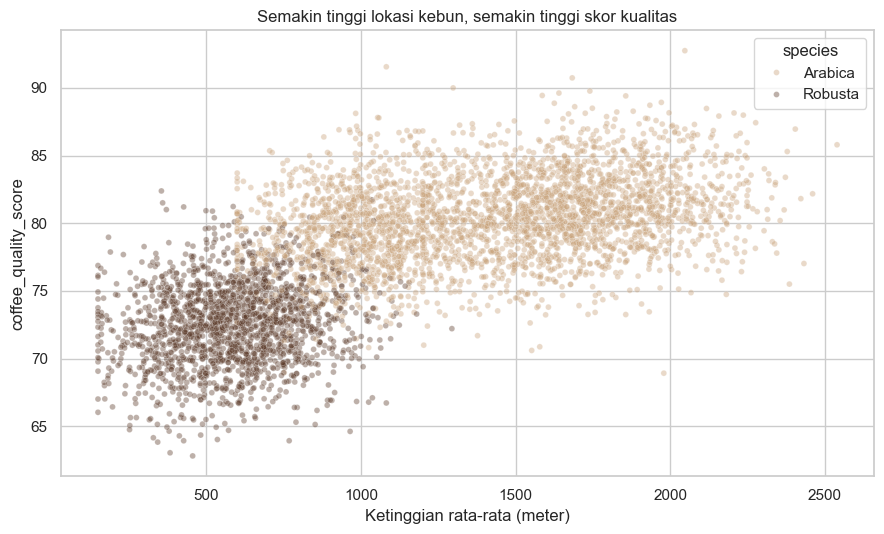

Korelasi ketinggian vs kualitas (keseluruhan): 0.68
  di dalam Arabica : 0.27
  di dalam Robusta : 0.13


In [35]:
# Mengambil 5.000 baris acak agar grafik tidak terlalu padat
sampel = df_clean.sample(5000, random_state=RANDOM_STATE)

# Membuat scatter plot ketinggian vs skor kualitas, warna dibedakan per spesies
plt.figure(figsize=(9, 5.5))
sns.scatterplot(data=sampel, x='altitude_mean_meters', y='coffee_quality_score',
                hue='species', alpha=0.4, s=18, palette=['#c8a27a', '#5b3a29'])
plt.title('Semakin tinggi lokasi kebun, semakin tinggi skor kualitas')
plt.xlabel('Ketinggian rata-rata (meter)')
plt.ylabel('coffee_quality_score')
plt.tight_layout()
plt.show()

# Menghitung korelasi ketinggian vs kualitas secara keseluruhan
print('Korelasi ketinggian vs kualitas (keseluruhan):',
      round(df_clean['altitude_mean_meters'].corr(df_clean['coffee_quality_score']), 2))

# Menghitung korelasi yang sama di dalam masing-masing spesies
for spesies, grup in df_clean.groupby('species'):
    print('  di dalam', spesies, ':', round(grup['altitude_mean_meters'].corr(grup['coffee_quality_score']), 2))

##### Secara keseluruhan korelasi ketinggian-kualitas sekitar *0,68*. Namun di dalam masing-masing spesies korelasinya jauh lebih lemah: sekitar # *0,27* pada Arabica dan *0,13* pada Robusta. Artinya sebagian besar pola "tinggi = berkualitas" muncul karena Arabica (rata-rata sekitar 1.440 m) # ditanam jauh lebih tinggi daripada Robusta (rata-rata sekitar 600 m), bukan semata-mata karena ketinggiannya.

### Temuan 3 - Negara asal memengaruhi kualitas dan harga

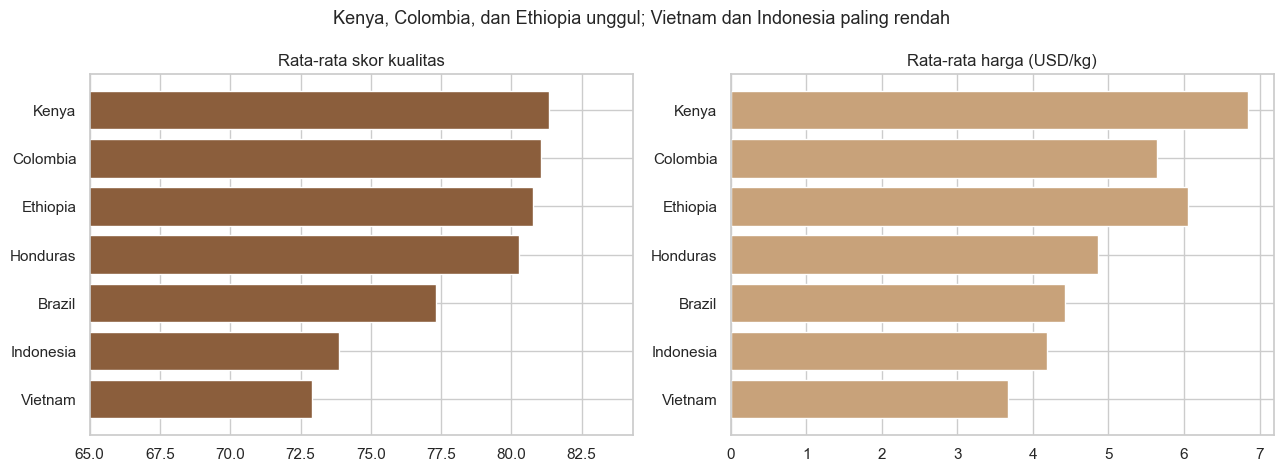

In [36]:
# Menghitung rata-rata skor kualitas dan harga per negara, diurutkan dari kualitas terendah
negara = (df_clean.groupby('country_of_origin')[['coffee_quality_score', 'price_usd_per_kg']]
          .mean().sort_values('coffee_quality_score'))

# Membuat dua grafik batang horizontal berdampingan
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
axes[0].barh(negara.index, negara['coffee_quality_score'], color='#8b5e3c')
axes[0].set_title('Rata-rata skor kualitas')
axes[0].set_xlim(65, negara['coffee_quality_score'].max() + 3)   # memotong sumbu agar selisih terlihat
axes[1].barh(negara.index, negara['price_usd_per_kg'], color='#c8a27a')
axes[1].set_title('Rata-rata harga (USD/kg)')

# Memberi judul utama berupa pesan temuan
plt.suptitle('Kenya, Colombia, dan Ethiopia unggul; Vietnam dan Indonesia paling rendah', fontsize=13)
plt.tight_layout()
plt.show()

Kenya memiliki skor sekitar **81,3** dan harga tertinggi (sekitar **USD 6,85/kg**), sedangkan Vietnam sekitar **72,9** dengan harga terendah (sekitar **USD 3,68/kg**). Brasil adalah penghasil terbanyak di dataset ini tetapi berada di tengah-tengah.

##### Temuan 4 - Harga lebih ditentukan oleh segmen pasar dan traceability daripada kualitas semata

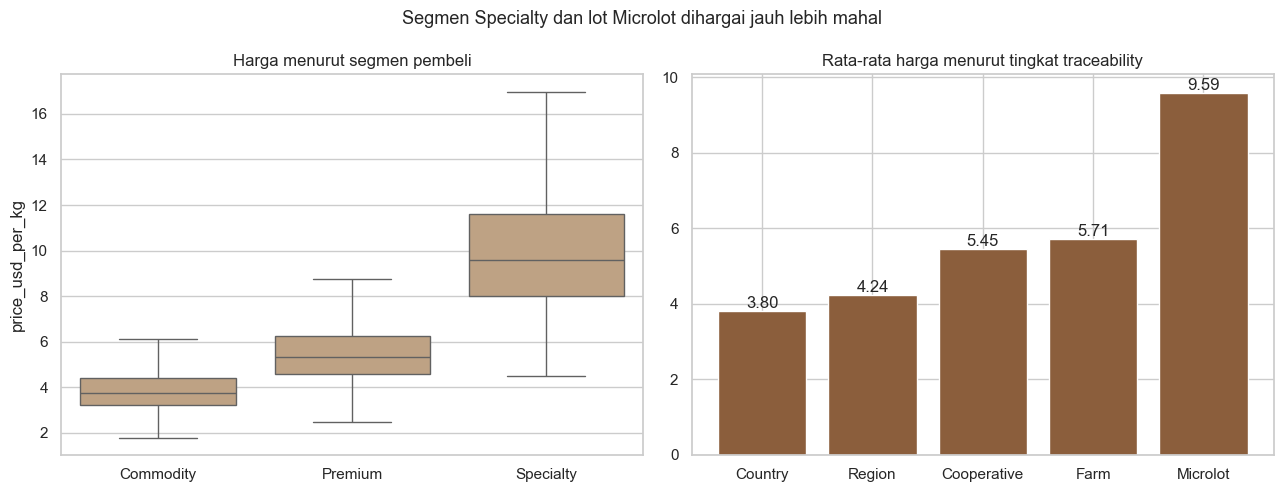

,price_usd_per_kg,coffee_quality_score
traceability_level,,
Country,3.80,77.44
Region,4.24,77.63
Cooperative,5.45,77.74
Farm,5.71,77.66
Microlot,9.59,77.53


In [37]:
# Membuat dua grafik berdampingan
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Grafik kiri: box plot harga menurut segmen pembeli (outlier ekstrem disembunyikan)
sns.boxplot(data=df_clean, x='intended_buyer_segment', y='price_usd_per_kg',
            order=['Commodity', 'Premium', 'Specialty'], showfliers=False, ax=axes[0], color='#c8a27a')
axes[0].set_title('Harga menurut segmen pembeli')
axes[0].set_xlabel('')

# Grafik kanan: rata-rata harga menurut tingkat traceability (urut dari yang paling umum)
urut = ['Country', 'Region', 'Cooperative', 'Farm', 'Microlot']
tr = df_clean.groupby('traceability_level')[['price_usd_per_kg', 'coffee_quality_score']].mean().loc[urut]
bars = axes[1].bar(tr.index, tr['price_usd_per_kg'], color='#8b5e3c')
axes[1].bar_label(bars, fmt='%.2f')
axes[1].set_title('Rata-rata harga menurut tingkat traceability')
axes[1].set_xlabel('')

# Memberi judul utama berupa pesan temuan
plt.suptitle('Segmen Specialty dan lot Microlot dihargai jauh lebih mahal', fontsize=13)
plt.tight_layout()
plt.show()

# Menampilkan tabel rata-rata harga dan kualitas per tingkat traceability
tr.round(2)

##### Rata-rata harga segmen *Specialty (sekitar USD 9,97/kg)** hampir tiga kali *Commodity (sekitar USD 3,87/kg)**, sedangkan selisih skor kualitasnya hanya sekitar 4 poin. Lot *Microlot* dihargai sekitar *USD 9,59/kg* vs *Country* sekitar *USD 3,80/kg*, padahal rata-rata kualitas tiap tingkat traceability hampir sama (sekitar 77,4-77,7). Artinya nilai jual juga dibentuk oleh *cerita dan keterlacakan* produk, bukan hanya mutu di cangkir.

##### Temuan 5 - Kualitas tinggi tidak otomatis berarti harga tinggi

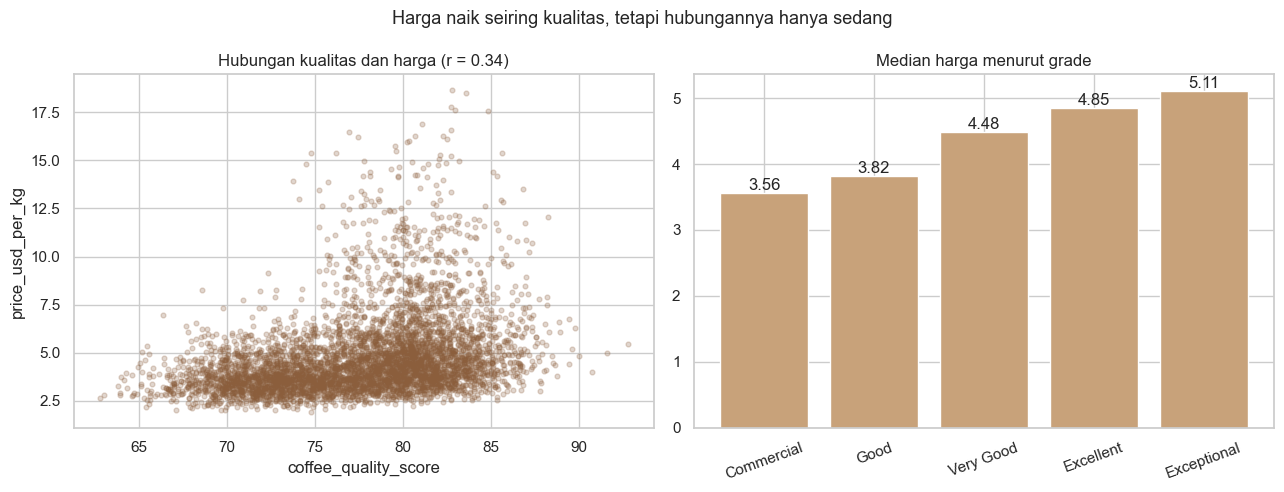

In [38]:
# Membuat dua grafik berdampingan
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Grafik kiri: scatter plot kualitas vs harga (sampel 5.000 baris)
sampel = df_clean.sample(5000, random_state=RANDOM_STATE)
axes[0].scatter(sampel['coffee_quality_score'], sampel['price_usd_per_kg'], alpha=0.25, s=12, color='#8b5e3c')
axes[0].set_xlabel('coffee_quality_score')
axes[0].set_ylabel('price_usd_per_kg')
r = df_clean['coffee_quality_score'].corr(df_clean['price_usd_per_kg'])   # koefisien korelasi
axes[0].set_title(f'Hubungan kualitas dan harga (r = {r:.2f})')

# Grafik kanan: median harga menurut grade, diurutkan dari grade terendah
urut_grade = ['Commercial', 'Good', 'Very Good', 'Excellent', 'Exceptional']
med = df_clean.groupby('quality_grade')['price_usd_per_kg'].median().loc[urut_grade]
bars = axes[1].bar(med.index, med.values, color='#c8a27a')
axes[1].bar_label(bars, fmt='%.2f')
axes[1].set_title('Median harga menurut grade')
axes[1].tick_params(axis='x', rotation=20)

# Memberi judul utama berupa pesan temuan
plt.suptitle('Harga naik seiring kualitas, tetapi hubungannya hanya sedang', fontsize=13)
plt.tight_layout()
plt.show()

##### Korelasi kualitas-harga hanya sekitar *0,34*. Median harga naik dari sekitar *USD 3,6/kg* (Commercial) ke sekitar *USD 5,1/kg* (Exceptional), tetapi kenaikannya jauh lebih landai dibanding perbedaan harga antar segmen pasar pada Temuan 4.

##### Kesimpulan ExDA
1. *Spesies* adalah pembeda kualitas terbesar. Ketinggian, suhu, dan kepadatan biji berkorelasi kuat dengan kualitas, tetapi sebagian besar karena ketiganya ikut berbeda antara Arabica dan Robusta; di dalam satu spesies pengaruh ketinggian jauh lebih lemah.
2. *Negara asal* dan *tingkat sangrai* (Light lebih tinggi dari Dark) juga memengaruhi kualitas.
3. *Harga* banyak dipengaruhi faktor komersial: segmen pembeli (Specialty), traceability (Microlot), dan sertifikasi tertentu; kualitas hanya menjelaskan sebagian.
4. Sertifikasi hampir tidak mengubah skor kualitas (rata-rata semua kategori sekitar 77,5-77,8) tetapi berhubungan dengan harga: Rainforest Alliance dan Multiple lebih mahal, sedangkan Fair Trade hampir sama dengan lot tanpa sertifikasi.
5. Metode proses *Anaerobic* terlihat paling tinggi, tetapi jumlah datanya kecil (sekitar 700 baris), sehingga perlu hati-hati menyimpulkan.
6. Semua temuan ini bersifat **asosiasi**, bukan sebab-akibat, dan data ini sintetis sehingga tidak bisa langsung digeneralisasi ke kondisi nyata.

##### 6. Data Splitting

*Keputusan:*
- *Target* `y` = `coffee_quality_score` (regresi).
- *Fitur dibuang:*`lot_id` (hanya pengelompokan), `quality_grade` (diturunkan dari target), `price_usd_per_kg` (hasil penjualan), dan lima skor rasa (hasil penilaian kualitas yang sama).
- *Pembagian 80% train : 20% test dengan `GroupShuffleSplit` berdasarkan `lot_id`.* Cara yang paling umum adalah `train_test_split(X, y, test_size=0.2, random_state=42)`, tetapi beberapa lot punya lebih dari satu baris (pengukuran ulang). Jika dipisah acak biasa, lot yang sama bisa muncul di train dan test sehingga skor evaluasi tampak lebih bagus dari kenyataannya.

In [39]:
# Menentukan kolom target
TARGET = 'coffee_quality_score'

# Menentukan kolom yang tidak dipakai sebagai fitur (ID, target, turunan target, dan skor rasa)
buang_dari_fitur = ['lot_id', 'coffee_quality_score', 'price_usd_per_kg', 'quality_grade'] + score_cols

# Memisahkan fitur (X), target (y), dan penanda kelompok (groups)
X = df_encoded.drop(columns=buang_dari_fitur)
y = df_encoded[TARGET]
groups = df_encoded['lot_id']

# Membagi data: 80% train dan 20% test, dengan lot_id yang sama selalu berada di sisi yang sama
gss = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=RANDOM_STATE)
idx_train, idx_test = next(gss.split(X, y, groups))

# Mengambil data train dan test berdasarkan indeks hasil pembagian
X_train, X_test = X.iloc[idx_train].copy(), X.iloc[idx_test].copy()
y_train, y_test = y.iloc[idx_train], y.iloc[idx_test]

# Menampilkan ukuran data train dan test
print('X_train:', X_train.shape, '| X_test:', X_test.shape)
print('Proporsi test: %.1f%%' % (len(X_test) / len(X) * 100))

# Memastikan tidak ada lot_id yang berada di train dan test sekaligus (harus 0)
print('lot_id yang ada di train dan test sekaligus:',
      len(set(groups.iloc[idx_train]) & set(groups.iloc[idx_test])))

X_train: (28283, 37) | X_test: (7067, 37)
Proporsi test: 20.0%
lot_id yang ada di train dan test sekaligus: 0


In [40]:
# Membandingkan statistik target pada data train dan test (sebaiknya mirip)
pd.DataFrame({'train': y_train.describe(), 'test': y_test.describe()}).round(2)

,train,test
count,28283.00,7067.00
mean,77.61,77.57
std,4.92,4.88
min,60.00,62.42
25%,73.81,73.82
50%,78.23,78.23
75%,81.32,81.34
max,94.18,90.74


##### Standardisasi (di-*fit* hanya pada data train)

In [41]:
# Menentukan kolom yang distandardisasi: fitur numerik dan kolom kalender panen
scale_cols = numeric_features + calendar_cols

# Membuat objek StandardScaler
scaler = StandardScaler()

# Membuat salinan data agar X_train dan X_test asli tetap tersimpan
X_train_scaled = X_train.copy()
X_test_scaled = X_test.copy()

# Mempelajari rata-rata dan simpangan baku dari data train, lalu menerapkannya ke data train
X_train_scaled[scale_cols] = scaler.fit_transform(X_train[scale_cols])

# Menerapkan skala yang sama ke data test (hanya transform, tidak fit ulang)
X_test_scaled[scale_cols] = scaler.transform(X_test[scale_cols])

# Memeriksa hasil: rata-rata sekitar 0 dan simpangan baku sekitar 1 pada data train
X_train_scaled[scale_cols].describe().loc[['mean', 'std']].round(2)

,farm_size_hectares,tree_age_years,altitude_mean_meters,avg_temp_c,avg_annual_rainfall_mm,humidity_pct,drying_duration_days,storage_months,bean_size_screen,moisture_pct,bean_density_g_ml,defect_rate_pct,lot_size_kg,harvest_calendar_year,harvest_month
mean,-0.0,0.0,0.0,-0.0,0.0,-0.0,-0.0,-0.0,-0.0,0.0,0.0,-0.0,0.0,-0.0,0.0
std,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0


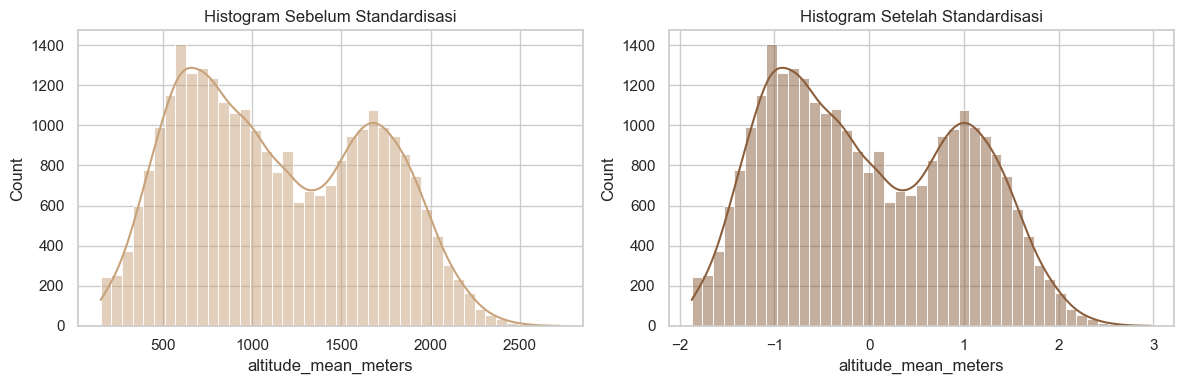

In [42]:
# Histogram sebelum dan sesudah standardisasi (contoh: altitude_mean_meters)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Sebelum standardisasi
sns.histplot(X_train['altitude_mean_meters'], kde=True, ax=axes[0], color='#c8a27a')
axes[0].set_title('Histogram Sebelum Standardisasi')

# Sesudah standardisasi
sns.histplot(X_train_scaled['altitude_mean_meters'], kde=True, ax=axes[1], color='#8b5e3c')
axes[1].set_title('Histogram Setelah Standardisasi')

plt.tight_layout()
plt.show()

##### Ringkasan
Data sudah melewati seluruh tahapan: *Collecting → Loading → Cleaning & Transformation → EDA → ExDA → Splitting*, dan siap dipakai untuk melatih model regresi pada `coffee_quality_score` (`X_train_scaled`, `X_test_scaled`, `y_train`, `y_test`).

In [ ]:
#### lalu sekarang kita ke Cross Validation Split

In [43]:
from sklearn import tree
from sklearn.model_selection import cross_val_score

# mendefinisikan atribut dan label pada dataset
x = X_train
y = y_train

# membuat model dengan decision tree regressor
clf = tree.DecisionTreeRegressor()

# mengevaluasi performa model dengan cross_val_score
scores = cross_val_score(clf, x, y, cv=5)
print(scores)

[0.71301122 0.70387475 0.72555151 0.72252263 0.71906053]
